<a href="https://colab.research.google.com/github/pi1024/PythonTutorial4/blob/main/Week_3_Data_Exploration_1016.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Exploration with Python

The goal of this session is to start to learn about Data Exploration.

> *“to generate many promising leads that you can explore later in depth”* (Wickham & Grolemund, 2017:1).

Exploring data can be undertaken using data analysis/modelling and visualisation and involves being inquisitive about the data and asking questions. The goal of this session is to whet your appetite for how we can explore data with Python and engage with exploratory investigation.  

Exercises for you to complete are clearly marked, as we have been doing in the Skills Development (Introduction to Python) Worksheets 1-4.

### Please note:
If you haven't completed the Skills Development (introduction to Python parts 1-4), please go back and complete them first before going through this worksheet. In this worksheet, we are assuming that you have already completed the Parts 1-4.

### Learning Objectives
By the end of this worksheet, you should be able to


1.   Introduce core Python libraries for Data Science (pandas, matplotlib, seaborn)
2.   Read Tabular, Excel, Web (HTML) and API (JSON) data into Python DataFrames
3.   Generate descriptive statistical summaries
4.   Explore distributions and continuous relationships usingt histograms and scatter plots

Last week we mainly focused on two data structures in Python that can be used to store data of different types/classes: (i) lists, dictionaries and (ii) data frames. In particular we spent time on the data frame as this is one of the most widely-used structures in Python because it can be used to store tabular data, e.g. tables in a database or spreadsheets.

This week we will explore data stored in a data frame mainly through the use of data visualisations, but also using descriptive summaries and cross tabulations.

## Basic Data Exploration with In-built Data

One of the greatest benefits of using popular langauges like Python is that it is easy to get started with some interesting datasets, already available within libraries. `Sklearn` is one of these libraries that you can use to get started, using the `sklearn.datasets` utility - [here's](https://scikit-learn.org/stable/datasets.html#datasets) some further information about the datasets and how to load them. You will notice that there are toy datasets, real world datasets and datasets that you can generate for different tasks. This is ideal for getting started with learning Python and conducting data analysis. We will use one such dataset in this example.

In order to load this dataset, you will first need to import `sklearn` and then use the California Housing Dataset. Once you follow this example, I would invite you to try out some other datasets.

In [ ]:
# By now, you should be aware that most of the code should be starting with importing key libraries - here, pandas and sklearn

import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load California Housing dataset from scikit-learn
housing_raw = fetch_california_housing(as_frame=True)

# Extract into a standard pandas DataFrame
housing = housing_raw.frame

# Inspect the first few rows
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


As you can see, we have several columns of numeric data, which makes it an excellent choice for some interesting analyses. First, we would like to get an understanding of the distribution of the numeric data. So, we will generate a full descriptive breakdown of all features (here, income (MedInc), house age, average rooms, average bedrooms, target house value). For this, we use the `describe()` function.

In [ ]:
# Display descriptive statistics: count, mean,
housing.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### Univariate data exploration: Histograms

To explore the distribution of a continuous variable (e.g. income, age, average rooms etc.) we can use a histogram. Let’s create a histogram of height using the hist() function and will generate a graph in the Output. In order to generate graphs, we will however need to import another library, called matplotlib.  

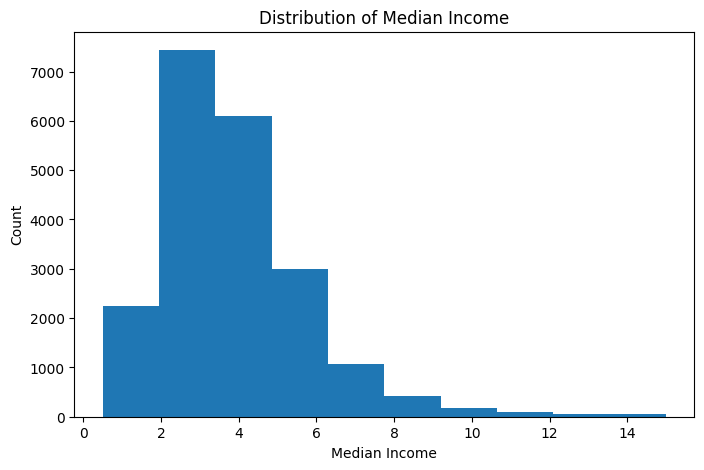

In [ ]:
import matplotlib.pyplot as plt
# Histogram of Median Income
plt.figure(figsize=(8, 5))
plt.hist(housing["MedInc"])
plt.title("Distribution of Median Income")
plt.xlabel("Median Income")
plt.ylabel("Count")
plt.show()

Now we can see a histogram of count of houses vs median income. MedInc is scaled in `$10,000` so the actual value would be the `shown value x 10,000`. Similarly, the housevalue is scaled in` $100,000`. You may also notice that we have 10 bins - this is the default option for the `hist()` function. It might be possible that 10 bins is the optimum number of bins for the histogram. However, you could change this value by adding another parameter to the `hist()` function call. We can also make the bins more visible by adding some edge colours, as below:

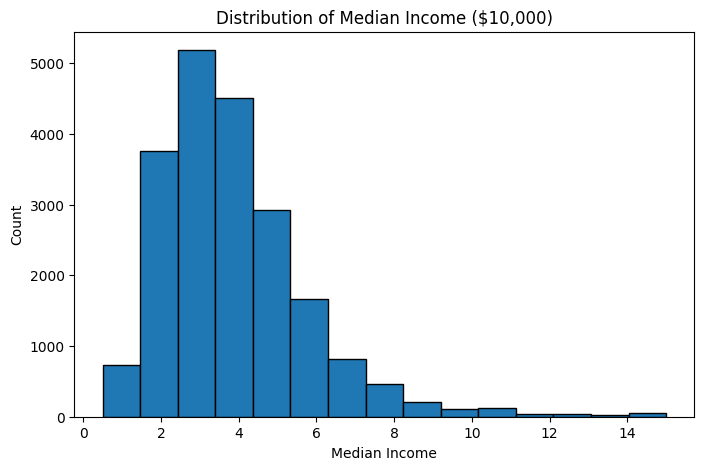

In [ ]:
# Histogram of Median Income
plt.figure(figsize=(8, 5))

# Let's add more bins, and add a edge colour to the bins

plt.hist(
    housing["MedInc"],
    edgecolor='black',
    bins=15
    )

plt.title("Distribution of Median Income ($10,000)")
plt.xlabel("Median Income")
plt.ylabel("Count")
plt.show()

As you can see, the number of bins can be changed, which is great. However, that means that you have to make a choice on the bin count. You could also leave it to the system to decide what's a good number, using 'auto'.

**&#9998; Exercise.** Look at the hist() function library and
1. use the 'auto' value for bin count, 2. set the bin colour as grey


(array([ 24.,  37.,  80., 110., 193., 248., 351., 571., 508., 644., 794.,
        753., 754., 938., 738., 798., 977., 840., 730., 887., 794., 616.,
        782., 737., 550., 524., 532., 441., 421., 455., 391., 329., 316.,
        234., 205., 290., 220., 164., 177., 136., 128.,  86.,  89.,  74.,
         87.,  78.,  80.,  67.,  64.,  48.,  50.,  32.,  40.,  23.,  20.,
         18.,  14.,  14.,  12.,  18.,  24.,  32.,  27.,  18.,  21.,  16.,
         18.,  11.,   8.,   3.,   8.,   7.,   3.,   5.,   5.,   8.,   6.,
          3.,   4.,   4.,   5.,   7.,   4.,   2.,   2.,   1.,   0.,   2.,
          2.,   1.,   0.,  52.]),
 array([ 0.4999    ,  0.65751087,  0.81512174,  0.97273261,  1.13034348,
         1.28795435,  1.44556522,  1.60317609,  1.76078696,  1.91839783,
         2.0760087 ,  2.23361957,  2.39123043,  2.5488413 ,  2.70645217,
         2.86406304,  3.02167391,  3.17928478,  3.33689565,  3.49450652,
         3.65211739,  3.80972826,  3.96733913,  4.12495   ,  4.28256087,
         

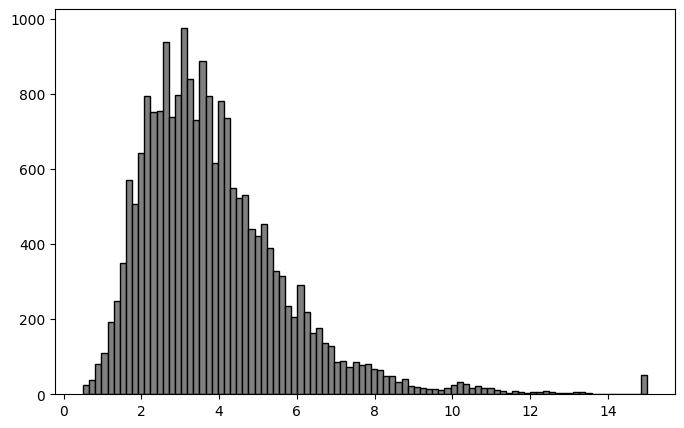

In [ ]:
# Your answer

plt.figure(figsize=(8, 5))

# Let's add more bins, and add a edge colour to the bins

plt.hist(
    housing["MedInc"],
    edgecolor='black',
    bins= 'auto',
    color = 'grey'
    )


### Multi-Plot layouts (side-by-side subplots)

When analysing multiple numeric variables simultaneously, it might be useful to study them side-by-side. Python's `matplotlib.pyplot.subplots()` is a helpful function that lets you arrange multiple charts in a grid.

Let's try to study house age and house price in such a way. This time, let's use 25 bins.

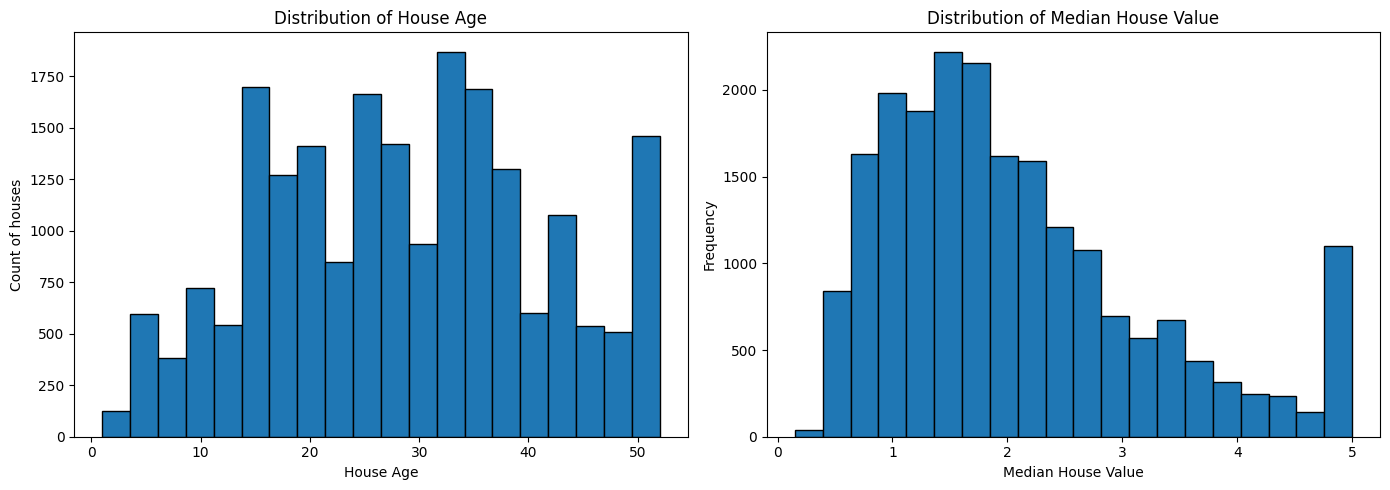

In [ ]:
# A 2-column figure layout would be ideal in this case, as we are only looking at 2 variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Housing Age Distribution
axes[0].hist(
    housing["HouseAge"], bins=20, edgecolor="black"
)
axes[0].set_title("Distribution of House Age")
axes[0].set_xlabel("House Age")
axes[0].set_ylabel("Count of houses")

# Plot 2: Median House Value Distribution
axes[1].hist(
    housing["MedHouseVal"], bins=20, edgecolor="black"
)
axes[1].set_title("Distribution of Median House Value")
axes[1].set_xlabel("Median House Value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**&#9998; Exercise.** Now that we created a composite of two histograms, analysing distributions of house age and house value, you should create a 3x2 matrix of histograms as below:


| | |
|---|---|
| House Value | House Age |
| Number of Rooms | Number of Bedrooms |
| Average occupancy | Population |

For the house value, given that this is a target variable, also colour the graph for median house value blue, and the others grey

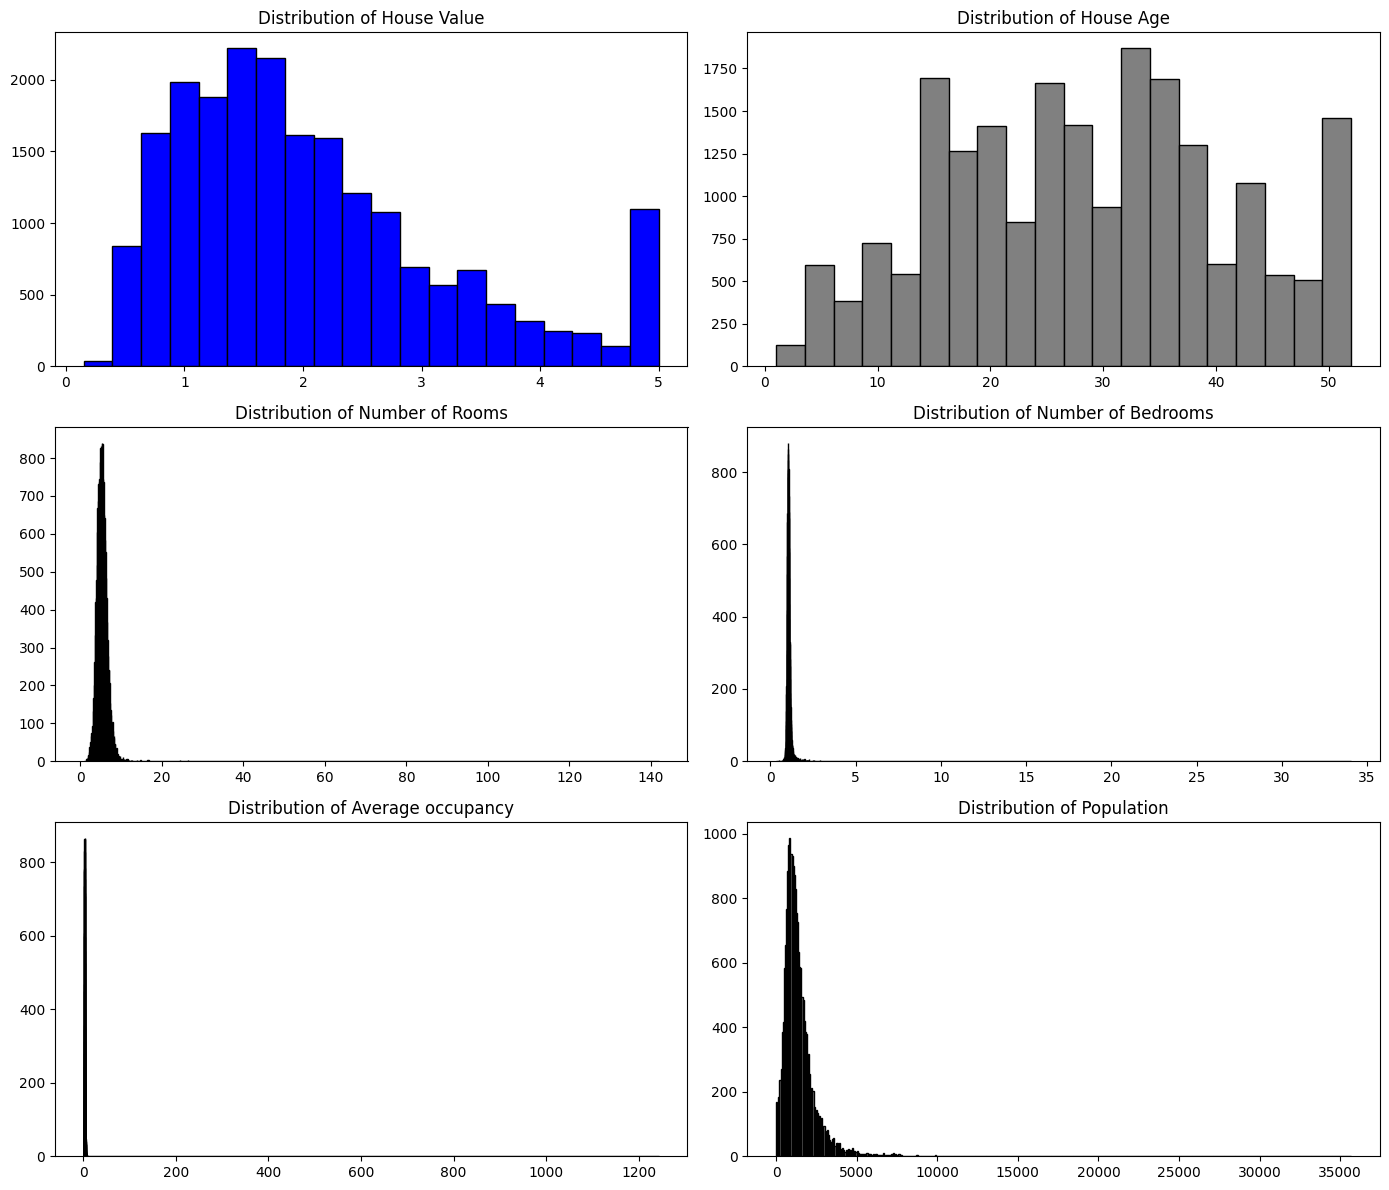

In [ ]:
# Your answer

fig, axes = plt.subplots(3, 2, figsize = (14,12))
#1
axes[0,0].hist(housing["MedHouseVal"], bins=20 , color="blue", edgecolor="black")
axes[0,0].set_title("Distribution of House Value")

#2
axes[0,1].hist(housing["HouseAge"], bins= 20, color="grey", edgecolor="black")
axes[0,1].set_title("Distribution of House Age")

#3
axes[1,0].hist(housing["AveRooms"], bins='auto', color="grey", edgecolor="black")
axes[1,0].set_title("Distribution of Number of Rooms")

#4
axes[1,1].hist(housing["AveBedrms"], bins='auto', color="grey", edgecolor="black")
axes[1,1].set_title("Distribution of Number of Bedrooms")

#5
axes[2,0].hist(housing["AveOccup"], bins='auto', color="grey", edgecolor="black")
axes[2,0].set_title("Distribution of Average occupancy")

#6
axes[2,1].hist(housing["Population"], bins='auto', color="grey", edgecolor="black")
axes[2,1].set_title("Distribution of Population")

plt.tight_layout()
plt.show()


In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


### Bivariate Exploration: Scatter Plots

Scatter plots are very helpful in revealing how two continuous variables could relate to each other. We will examine if income corresponds to home value.


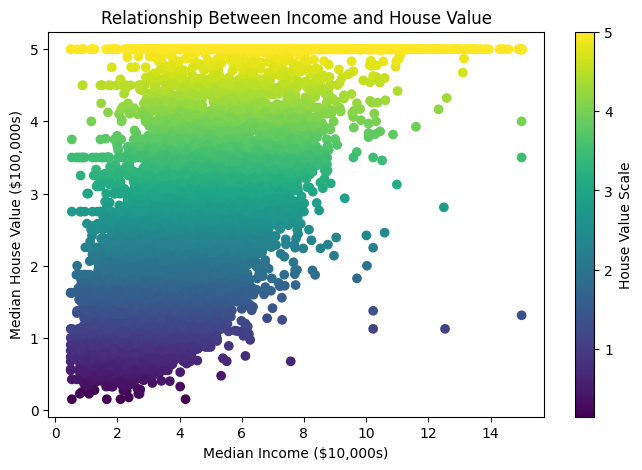

In [ ]:
# Scatter Plot: Income vs. House Value
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    housing["MedInc"],
    housing["MedHouseVal"],
    c=housing["MedHouseVal"],
    cmap="viridis",
)

plt.title(
    "Relationship Between Income and House Value",
)
plt.xlabel("Median Income ($10,000s)")
plt.ylabel("Median House Value ($100,000s)")

# Add color scale legend
cbar = plt.colorbar(scatter)
cbar.set_label("House Value Scale", fontsize=10)

plt.show()

Inspecting the graph, we notice that as the median income shifts towards the right along the x-axis, median house value shifts upwards along the y-axis. This offers some initial insights that tell us that there's a potential positive relationship which indicates that wealthier owners have higher house value - that relationship might be an obvious one, but it's good to see the graph reflect this. However, some outliers also show up, where high income also have houses that are spread across the different values. On the top, at the highest median values, we also note a spread across the different median income ranges.

## Importing tabular data into DataFrames

As you may recollect from the previous worksheets, we can import CSV or TSV files into DataFrames and perform subsequent analysis. For this, we will use the `read_csv` function. Even if we have to read a TSV (tab separated value), we can use `read_csv`, just specifying the `sep` parameter. There are two ways you can upload the files - either through connecting with Google Drive (like the previous worksheets), or by uploading it with a pop-up. Let's try the pop-up method first, with a CSV file.

In [ ]:
from google.colab import files
import pandas as pd

print("Please select and upload your CSV file:")
uploaded = files.upload()
# pick up the filename
filename = list(uploaded.keys())[0]

#read the file
free_school_meals = pd.read_csv(filename)

# Print the first few rows
free_school_meals.head()

Please select and upload your CSV file:


Saving freeschoolmeals (1).csv to freeschoolmeals (1).csv


,SchoolName,SchoolPhase,Year,TotalPupils,TotalFSM,FSMTaken
0,Acomb Primary School,Primary,2014,232,14,6.0
1,Archbishop Of Yorks Ce Junior,Primary,2014,242,8,5.0
2,Badger Hill Primary School,Primary,2014,167,6,9999.0
3,Bishopthorpe Infant School,Primary,2014,182,6,9999.0
4,Burton Green Primary School,Primary,2014,202,51,35.0


Since we have now loaded the school meals dataset, let's try conducting some analysis of the data. For this, we will use a histogram and a scatterplot, just like before.

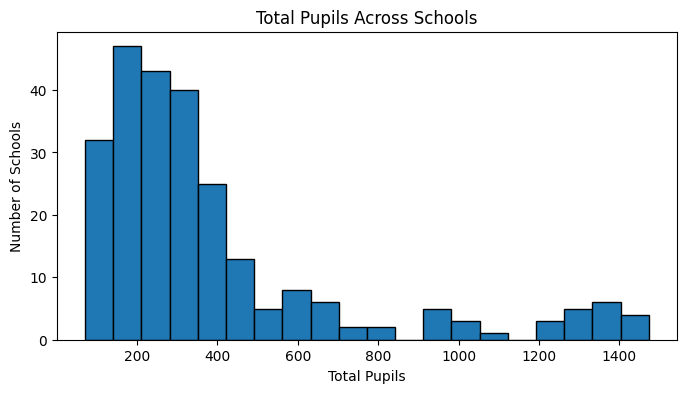

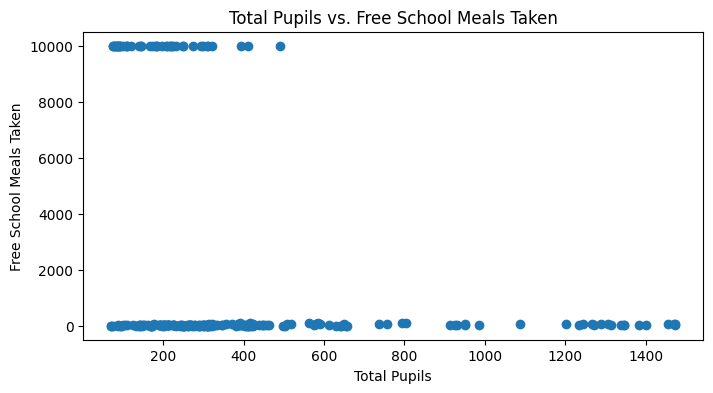

In [ ]:
# Total Pupils Histogram
plt.figure(figsize=(8, 4))
plt.hist( free_school_meals["TotalPupils"], bins='auto', edgecolor="black",
)
plt.title("Total Pupils Across Schools")
plt.xlabel("Total Pupils")
plt.ylabel("Number of Schools")
plt.show()

# Scatter Plot: Total Pupils vs Meals Taken
plt.figure(figsize=(8, 4))
plt.scatter(
    free_school_meals["TotalPupils"],
    free_school_meals["FSMTaken"]
)
plt.title("Total Pupils vs. Free School Meals Taken")
plt.xlabel("Total Pupils")
plt.ylabel("Free School Meals Taken")
plt.show()

Now let's use the Google drive option. Remember, you will need to allow Google Colab access to your Google Drive.

First you will need to upload the test.tsv file to the top level of your Google Drive (login to Google Drive, place the file on MyDrive)

In [ ]:
from google.colab import drive
import pandas as pd

# Mount your Google Drive
drive.mount("/content/drive")

# Read file directly from your Drive folder - you can keep the file on the root of your MyDrive (Go to https://drive.google.com/drive/u/0/home and then place this in the MyDrive folder)
file_path = "/content/drive/MyDrive/Material/test.tsv"
df = pd.read_csv(file_path,sep="\t", header=None)

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,0,1,2
0,1,6,a
1,2,7,b
2,3,8,c
3,4,9,d
4,5,10,e


##Reading Excel Files

In addition to the CSV/TSV files, you can also read-in Excel files, and you should mention the sheet name in the file.



In [ ]:
# Read Excel file, specifying sheet name (here, 'Data')

print("Please select and upload your excel file:")
uploaded = files.upload()
# pick up the filename
filename = list(uploaded.keys())[0]

hiv_df = pd.read_excel(
    filename, sheet_name="Data"
)
hiv_df.head()

Please select and upload your excel file:


Saving indicator hiv estimated prevalence_ 15-49.xlsx to indicator hiv estimated prevalence_ 15-49.xlsx


,Estimated HIV Prevalence% - (Ages 15-49),1979,1980,1981,1982,1983,1984,1985,1986,1987,...,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011
0,Abkhazia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.06,0.06,0.06
2,Akrotiri and Dhekelia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.06,0.06,0.1,0.1,0.1,0.1,0.1,NaN,NaN,NaN


Let's now look at the HIV prevalence distribution across 1980, 1990, and 2000

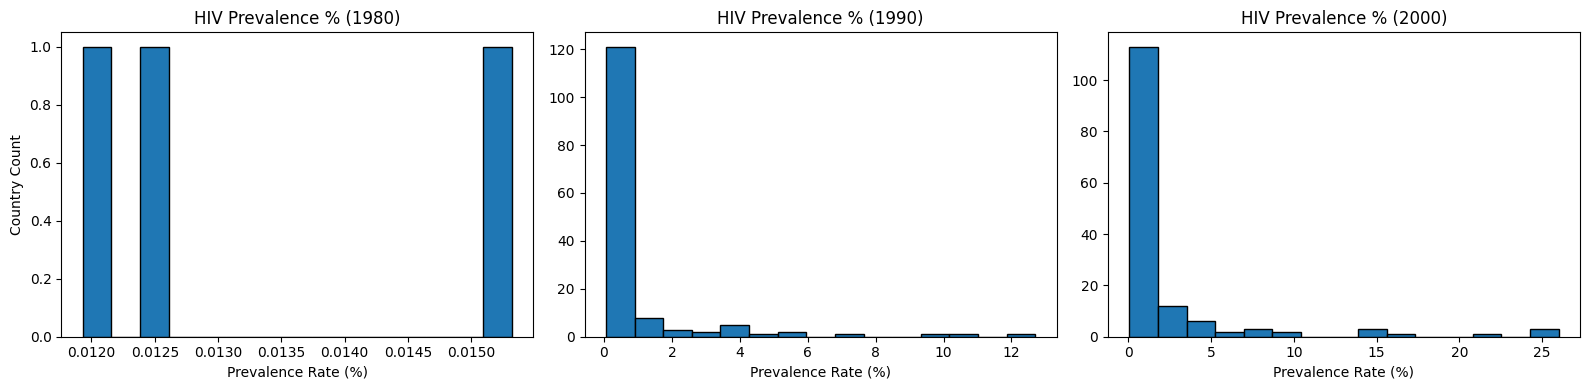

In [ ]:
# Filter missing values and plot comparative histograms across three decades
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Year 1980
axes[0].hist(hiv_df[1980], bins=15, edgecolor="black")
axes[0].set_title("HIV Prevalence % (1980)")
axes[0].set_xlabel("Prevalence Rate (%)")
axes[0].set_ylabel("Country Count")

# Year 1990
axes[1].hist(hiv_df[1990], bins=15, edgecolor="black")
axes[1].set_title("HIV Prevalence % (1990)")
axes[1].set_xlabel("Prevalence Rate (%)")

# Year 2000
axes[2].hist(hiv_df[2000], bins=15, edgecolor="black")
axes[2].set_title("HIV Prevalence % (2000)")
axes[2].set_xlabel("Prevalence Rate (%)")

plt.tight_layout()
plt.show()

## Web Scraping and Data Extraction from HTML

You may already remember using `requests` to download content as JSON by querying APIs. We can, however, use the same library to download raw HTML content over HTTP.

It is very important to note what exactly is happening here. We are sending a request to a server to download HTML content. However, we must announce who we are, as it is a key component of responsible web scraping and digital etiquette - without this announcement, all the server will know about us is our IP and that could raise concerns of bot-like behaviour (which could lead to automatic server blocks like `403 Forbidden`). Therefore, we should provide further information using User-Agent parameter. You should use a descriptive, accountable identifier that contains your project name: `{"User-Agent": "CityDataCollector, a student data analysis project (YOUREMAIL@university.ac.uk) "}`, which aligns with real-world scraping standards and server expectations.

More information [here](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy).

In [ ]:
import requests

# Send HTTP GET request to target web address
url = "https://en.wikipedia.org/wiki/Sheffield"

headers = {"User-Agent": "CityDataCollector_V0.1, a student data analysis project (<YOUR EMAIL>@university.ac.uk)"}
wikipedia_response = requests.get(url, headers=headers)
print (wikipedia_response.content)

b'<!DOCTYPE html>\n<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard skin-underline-clientpref-browser" lang="en" dir="ltr">\n<head>\n<meta charset="UTF-8">\n<title>Sheffield - Wikipedia</title>\n<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-fea

As you will see, you can see that the response comes in as HTML - if you copy this text, and paste into your browser `view-source:https://en.wikipedia.org/wiki/Sheffield`, you should be able to see how it looks. If you are interested, you can copy the entire text into a text editor (like notepad) and save it as an HTML file, and then open it in a browser.

However, that's not very useful as the text needs to be processed as HTML content.

In Python, we can use a library called `BeautifulSoup`. We already downloaded the HTML markup, now saved into `wikipedia_response` so we will work with that, to avoid re-downloading the content.

If you investigate the HTML page, you will notice that there are tags marked up as `<h1>, <h2>` etc. We will make use of the tags and print them out - first, we will print out the `title`

In [ ]:
from bs4 import BeautifulSoup
# Parse HTML using BeautifulSoup
soup = BeautifulSoup(wikipedia_response.content, "html.parser")

# extract the title
title = soup.find("title").text
print("Page title:", title)

Page title: Sheffield - Wikipedia


If you look at the HTML content, you will note that there is a tag called 'title', which gets queried and then returned.
`<title>Sheffield - Wikipedia</title>`

You may ask what tags are in HTML - HTML tags are keywords that are enclosed by angle brackets '<' and '>' and these are used to organise and structure web content. Typically used tags are headings (as marked up by 'h1', 'h2' ...), paragraphs, images, links, tables, forms, etc. Tags are interpreted by your web browser to 'render' the HTML in a well organised way.

Similar to the previous case of looking up the title, we can 'search' for other tags. For example, h1 (highest level of heading in a page), h2 (the next level) etc. Let's then look at the structure of the page by seeing the top two levels.

In [ ]:
top_heading = soup.find("h1")

#this extracts the top heading tag. You will notice there are additional attributes
#These are often links or specific classes or instructions.
print (top_heading)

#as you may notice, the attributes are distracting, but what we are looking for is the text between the <h1> and </h1>
#Soup provides a nice clean way of extracting this by looking at the 'text'

print (top_heading.text)
#you will see in the next line, we have 'Sheffield' printed out


<h1 class="firstHeading mw-first-heading" id="firstHeading"><span dir="ltr" lang="en"><span class="mw-page-title-main">Sheffield</span></span></h1>
Sheffield


Now let's try to print out all the `<h2>` content. However, some tags get repeated multiple times so we may need to iterate and find all the `<h2>` content throughout the HTML.

In [ ]:
second_level = soup.find_all("h2")
print (second_level) # by using find_all, we can now extract a list of all h2 elements

#iterate over all the h2 headings and print them out one at a time

for heading in second_level:
  print (heading.text)

[<h2 class="vector-pinnable-header-label">Contents</h2>, <h2 id="Toponymy">Toponymy</h2>, <h2 id="History">History</h2>, <h2 id="Governance">Governance</h2>, <h2 id="Geography">Geography</h2>, <h2 id="Demographics">Demographics</h2>, <h2 id="Economy">Economy</h2>, <h2 id="Transport">Transport</h2>, <h2 id="Education">Education</h2>, <h2 id="Religion">Religion</h2>, <h2 id="Sport">Sport</h2>, <h2 id="Landmarks">Landmarks</h2>, <h2 id="Culture">Culture</h2>, <h2 id="Notable_people">Notable people</h2>, <h2 id="Public_services">Public services</h2>, <h2 id="International_relations">International relations</h2>, <h2 id="Freedom_of_the_City">Freedom of the City</h2>, <h2 id="See_also">See also</h2>, <h2 id="Notes">Notes</h2>, <h2 id="References">References</h2>, <h2 id="Sources">Sources</h2>, <h2 id="Further_reading">Further reading</h2>, <h2 id="External_links">External links</h2>]
Contents
Toponymy
History
Governance
Geography
Demographics
Economy
Transport
Education
Religion
Sport
Landma

Similarly, we can also look for a specific tag and a specific class. In Wikipedia pages, the infobox is a key source of information. So, we will extract all the items from a specific class called 'infobox'. Once we do this, we will find all the links provided in the table, by using the find_all function. Links are represented by the `a` tag

In [ ]:
infobox = soup.find("table", class_="infobox")
#this prints out all the items of the infobox.
# print (infobox)

all_links = infobox.find_all("a")
# print (all_links)

for link in all_links:
  print (link) # you will notice that the link is embedded in 'href'
  # that's why we need to extract the hrefs
  print (link.get("href")) #gets the actual URL

<a href="https://en.wikipedia.org/wiki/City_status_in_the_United_Kingdom" rel="mw:WikiLink" title="City status in the United Kingdom">City</a>
https://en.wikipedia.org/wiki/City_status_in_the_United_Kingdom
<a href="https://en.wikipedia.org/wiki/Metropolitan_borough" rel="mw:WikiLink" title="Metropolitan borough">metropolitan borough</a>
https://en.wikipedia.org/wiki/Metropolitan_borough
<a class="mw-file-description" href="https://en.wikipedia.org/wiki/File:Sheffield_16-Sep-22-2.jpg"><img class="mw-file-element" data-file-height="3024" data-file-type="bitmap" data-file-width="4032" decoding="async" height="194" loading="lazy" resource="https://en.wikipedia.org/wiki/File:Sheffield_16-Sep-22-2.jpg" src="//thumb.wikimedia.org/wikipedia/commons/thumb/a/a7/Sheffield_16-Sep-22-2.jpg/330px-Sheffield_16-Sep-22-2.jpg?utm_source=en.wikipedia.org&amp;utm_campaign=parser&amp;utm_content=thumbnail" srcset="//thumb.wikimedia.org/wikipedia/commons/thumb/a/a7/Sheffield_16-Sep-22-2.jpg/960px-Sheffield

**&#9998; Exercise.** You should now look at how images are encoded in HTML, find the appropriate tag and the URL for images in HTML.

Extract image URLs from the infobox in `wikipedia_response` and then print out the width and height of these images. However, in printing the image URLs, filter out the ones that are under 100 pixels in height and width.

**hint:** in doing this, you will realise that the width and height needs to be converted to an integer (numeric) format as python takes this as a string.

In [ ]:
# Your answer
from bs4 import BeautifulSoup
soup = BeautifulSoup(wikipedia_response.text, "html.parser")

infobox = soup.find("table", class_="infobox")

images = infobox.find_all("img")
# see the structure
print(images)

for context in images:
  if (int(context.get('width')) > 100) and (int(context.get('height')) > 100):
    print(context.get('resource'))



[<img class="mw-file-element" data-file-height="3024" data-file-type="bitmap" data-file-width="4032" decoding="async" height="194" loading="lazy" resource="https://en.wikipedia.org/wiki/File:Sheffield_16-Sep-22-2.jpg" src="//thumb.wikimedia.org/wikipedia/commons/thumb/a/a7/Sheffield_16-Sep-22-2.jpg/330px-Sheffield_16-Sep-22-2.jpg?utm_source=en.wikipedia.org&amp;utm_campaign=parser&amp;utm_content=thumbnail" srcset="//thumb.wikimedia.org/wikipedia/commons/thumb/a/a7/Sheffield_16-Sep-22-2.jpg/960px-Sheffield_16-Sep-22-2.jpg?utm_source=en.wikipedia.org&amp;utm_campaign=parser&amp;utm_content=thumbnail 2x" width="258"/>, <img class="mw-file-element" data-file-height="3782" data-file-type="bitmap" data-file-width="5482" decoding="async" height="91" loading="lazy" resource="https://en.wikipedia.org/wiki/File:Sheffield_Town_Hall_(27475677653).jpg" src="//thumb.wikimedia.org/wikipedia/commons/thumb/3/33/Sheffield_Town_Hall_%2827475677653%29.jpg/250px-Sheffield_Town_Hall_%2827475677653%29.jpg?u

Working with JSON data

In the previous section, we were working with XML data structures. We will now look at working with JSON data. This was something we covered in the previous weeks' content, where we used APIs like cat facts, open meteo API etc. For this, we will use requests again. We will use the data from [Citibike NYC API](https://citibikenyc.com/) and look at stations - this [link](https://gbfs.citibikenyc.com/gbfs/en/station_information.json) provides a JSON file that has all the details of bike parking facilities.

In [ ]:
import requests

citibike_stations = "https://gbfs.citibikenyc.com/gbfs/en/station_information.json"
response = requests.get(citibike_stations)

# as before we convert the data to a python dictionary

stations = response.json()
# print(stations)

# and then convert to a python dataframe

stations = pd.DataFrame(stations['data']['stations'])
stations.head()


,station_id,name,short_name,lon,lat,region_id,capacity,rental_uris,rental_methods,has_kiosk,station_type,external_id,electric_bike_surcharge_waiver,eightd_station_services,eightd_has_key_dispenser
0,3eb10c63-ea4c-4161-b07d-a29034f7367a,Brook Ave & E 141 St,7740.08,-73.917875,40.809619,71,0,{'android': 'https://bkn.lft.to/lastmile_qr_sc...,"[KEY, CREDITCARD]",True,classic,3eb10c63-ea4c-4161-b07d-a29034f7367a,False,[],False
1,ba33c334-e17d-4478-ae3c-9c2f4dbfbb51,51 Ave & 61 St,5923.02,-73.903870,40.735680,71,0,{'android': 'https://bkn.lft.to/lastmile_qr_sc...,"[KEY, CREDITCARD]",True,classic,ba33c334-e17d-4478-ae3c-9c2f4dbfbb51,False,[],False
2,06439006-11b6-44f0-8545-c9d39035f32a,Vesey St & Church St,5216.06,-74.010472,40.712220,71,78,{'android': 'https://bkn.lft.to/lastmile_qr_sc...,"[KEY, CREDITCARD]",True,classic,06439006-11b6-44f0-8545-c9d39035f32a,False,[],False
3,1986707977001495180,21 St & 20 Ave,7363.03,-73.912731,40.783936,71,19,{'android': 'https://bkn.lft.to/lastmile_qr_sc...,"[KEY, CREDITCARD]",True,classic,1986707977001495180,False,[],False
4,1795146692060860976,Longfellow Ave & Aldus St,7983.02,-73.887629,40.823194,71,24,{'android': 'https://bkn.lft.to/lastmile_qr_sc...,"[KEY, CREDITCARD]",True,classic,1795146692060860976,False,[],False


You will see now that you have the data in a dataframe, so we can easily do a lot of interesting analysis.

**&#9998; Exercise.** You should first study the distribution of the capacities of all bike stations, and then create a histogram.

count    2518.000000
mean       29.533360
std        17.407485
min         0.000000
25%        19.000000
50%        23.000000
75%        33.000000
max       123.000000
Name: capacity, dtype: float64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2518 entries, 0 to 2517
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   station_id                      2518 non-null   object 
 1   name                            2518 non-null   object 
 2   short_name                      2518 non-null   object 
 3   lon                             2518 non-null   float64
 4   lat                             2518 non-null   float64
 5   region_id                       2505 non-null   object 
 6   capacity                        2518 non-null   int64  
 7   rental_uris                     2518 non-null   object 
 8   rental_methods                  2518 non-null   object 
 9   has_kiosk         

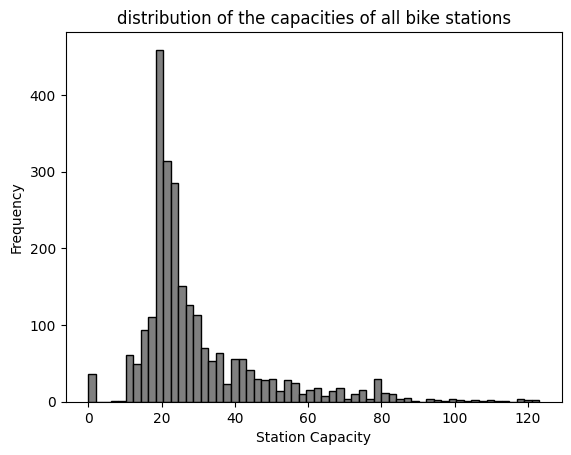

In [ ]:
# Your answer

import requests

citibike_stations = "https://gbfs.citibikenyc.com/gbfs/en/station_information.json"
response = requests.get(citibike_stations)

stations = response.json()

stations = pd.DataFrame(stations['data']['stations'])
# distribution
print(stations["capacity"].describe())
stations.info()
plt.hist(
    stations["capacity"],
    edgecolor='black',
    bins= 'auto',
    color = 'grey'
  )


plt.title("distribution of the capacities of all bike stations")
plt.xlabel("Station Capacity")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Your answer